In [1]:
import os 
print("Current folder:", os.getcwd())
print("Files here:", os.listdir())

Current folder: C:\Users\anubh\AI Automation project
Files here: ['.ipynb_checkpoints', 'app.py', 'data', 'job_matcher.py', 'libraries.ipynb', 'outputs', 'resume_parser.py', 'skill_extractor.py', 'test.ipynb', 'Untitled.ipynb', '__pycache__']


In [2]:
from resume_parser import parse_resume

print("Resume parser imported successfully!")

Resume parser imported successfully!


In [3]:
import os
print(os.getcwd())

C:\Users\anubh\AI Automation project


In [7]:
import importlib
import resume_parser

importlib.reload(resume_parser)

from resume_parser import parse_resume

In [8]:
r1 = parse_resume("data/resumes/01_Aarav_Sharma_Strong.pdf")
r2 = parse_resume("data/resumes/02_Priya_Nair_Strong.pdf")

print("AARAV SHARMA")
print(r1["name"], r1["email"], r1["phone"])
print(r1["education"], r1["experience_years"])

print("\nPRIYA NAIR")
print(r2["name"], r2["email"], r2["phone"])
print(r2["education"], r2["experience_years"])

AARAV SHARMA
Strong Sample aarav.sharma.sample@email.test +91 90000 10001
Final-year B.Tech Computer Science student with hands-on experience building Python machine learning projects,; B.Tech, Computer Science 0

PRIYA NAIR
Strong Sample priya.nair.sample@email.test +91 90000 10002
M.Sc. Data Science student with practical exposure to statistical analysis, NLP, supervised learning, and data; M.Sc. Data Science; Eastwood University | 2024–2026 | CGPA: 8.9/10 0


In [10]:
from skill_extractor import extract_skills
print(extract_skills(r1["text"]))

['git', 'github', 'matplotlib', 'numpy', 'pandas', 'power bi', 'python', 'scikit-learn', 'sql', 'statistics']


In [25]:
import glob, pandas as pd
from job_matcher import match_candidates, make_summary

jd = """Looking for a Python developer with machine learning, pandas, numpy,
scikit-learn, SQL and git. Good communication and teamwork required."""

cands = [parse_resume(p, p.replace("\\","/").split("/")[-1]) for p in glob.glob("data/resumes/01_Aarav_Sharma_Strong.pdf")]
ranked = match_candidates(jd, cands)
for c in ranked:
    print(c["name"], c["match_score"], "| missing:", c["missing_skills"])

Strong Sample 42.8 | missing: ['communication', 'teamwork']


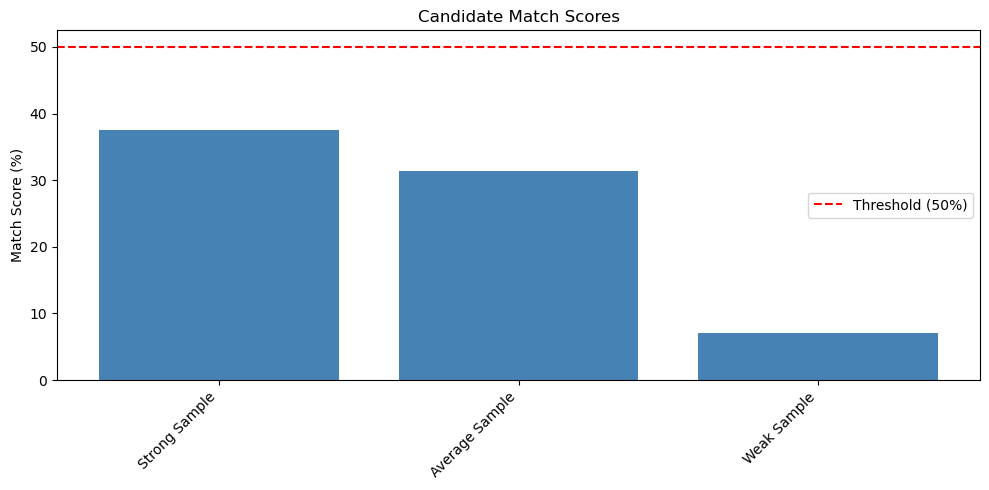

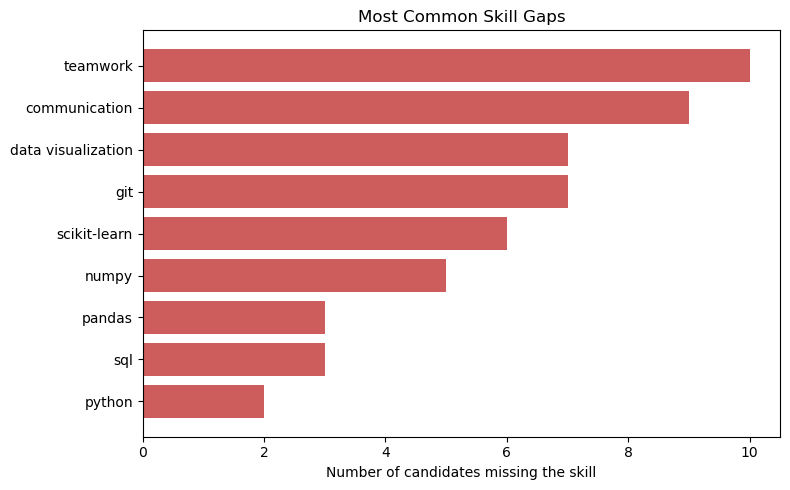

['score_comparison.png', 'shortlisted.csv', 'skill_gap_chart.png', 'smarthire_report.csv']


In [26]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from resume_parser import parse_resume
from job_matcher import match_candidates

os.makedirs("outputs", exist_ok=True)

jd = """We are looking for a Python developer with machine learning, pandas, numpy,
scikit-learn, SQL, git and data visualization skills. Good communication and teamwork required."""

cands = [parse_resume(p, os.path.basename(p)) for p in glob.glob("data/resumes/*.pdf")]
ranked = match_candidates(jd, cands)
threshold = 50

df = pd.DataFrame([{
    "Rank": i + 1, "Name": c["name"], "Email": c["email"], "Phone": c["phone"],
    "Experience (yrs)": c["experience_years"], "Education": c["education"],
    "Match Score": c["match_score"], "Text Similarity": c["text_score"],
    "Skill Match": c["skill_score"],
    "Matched Skills": ", ".join(c["matched_skills"]),
    "Missing Skills": ", ".join(c["missing_skills"]),
    "Shortlisted": "Yes" if c["match_score"] >= threshold else "No",
} for i, c in enumerate(ranked)])

# 1. CSV reports
df.to_csv("outputs/smarthire_report.csv", index=False)
df[df["Shortlisted"] == "Yes"].to_csv("outputs/shortlisted.csv", index=False)

# 2. Score comparison chart
plt.figure(figsize=(10, 5))
plt.bar(df["Name"], df["Match Score"], color="steelblue")
plt.axhline(threshold, color="red", linestyle="--", label=f"Threshold ({threshold}%)")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Match Score (%)")
plt.title("Candidate Match Scores")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/score_comparison.png", dpi=150)
plt.show()

# 3. Skill gap chart
missing = Counter(s for c in ranked for s in c["missing_skills"])
if missing:
    skills, counts = zip(*missing.most_common(10))
    plt.figure(figsize=(8, 5))
    plt.barh(skills[::-1], counts[::-1], color="indianred")
    plt.xlabel("Number of candidates missing the skill")
    plt.title("Most Common Skill Gaps")
    plt.tight_layout()
    plt.savefig("outputs/skill_gap_chart.png", dpi=150)
    plt.show()

print(os.listdir("outputs"))